# PPO from Scratch, Curiosity (RND), MiniGrid and Ray RLlib

* DQN → tuning → policy gradients → **PPO and curiosity***

The [Hugging Face Deep RL Course, Unit 5](https://huggingface.co/learn/deep-rl-course/unit5/introduction) trains two
agents with Unity ML-Agents:
- **SnowballTarget**, with PPO
- **Pyramids**, a sparse-reward task, with PPO plus a curiosity bonus called **RND**

There, the algorithms are a black box behind a YAML file and the `mlagents-learn` command. The Python side of
ML-Agents has also stalled: it needs exactly Python 3.10.1–3.10.12, and the course's game builds are Linux-only.

This notebook keeps the **ideas** of Unit 5, uses **maintained, cross-platform tools**, and opens the black box:

| Part | What | Replaces in the course |
|---|---|---|
| A | **PPO from scratch**: clipped surrogate, epochs and mini-batches, diagnostics | ML-Agents' PPO trainer |
| B | **RND curiosity from scratch** on MountainCar, a minimal sparse-reward task | the `rnd:` reward signal |
| C | **MiniGrid DoorKey**: find the key, open the door, reach the goal. PPO vs PPO + RND | Pyramids |
| D | **Ray RLlib**: the same task with industrial-strength, parallel PPO | `mlagents-learn` |
| E | Appendix: ML-Agents, if you still want it | |

Everything runs on macOS, Linux and Windows. You need `gymnasium`, `torch`, `matplotlib` and `minigrid`, plus
`ray[rllib]` for Part D.

## Where PPO comes from

In notebook 5, A2C took **one** gradient step per rollout and then threw the data away. It can't safely take more:
after one step the policy has changed, so the data no longer comes from the current policy, and large steps can
wreck a good policy (we saw A2C wobble late in training).

**PPO** (Schulman et al., 2017) reuses each rollout for **several epochs of mini-batch updates**, but keeps every update
small. It compares the new and old probability of each action, $r_t(\theta) = \frac{\pi_\theta(a_t \mid s_t)}{\pi_{\theta_\text{old}}(a_t \mid s_t)}$,
and **clips** the objective so there is nothing to gain from moving $r_t$ outside $[1-\epsilon,\, 1+\epsilon]$:

$$\mathcal{L}^{\text{CLIP}}(\theta) = \mathbb{E}_t\Big[\min\big(r_t(\theta)\,\hat A_t,\; \text{clip}(r_t(\theta), 1-\epsilon, 1+\epsilon)\,\hat A_t\big)\Big]$$

- If $\hat A_t > 0$ (the action was good), its probability is raised, but by at most a factor of $1+\epsilon$.
- If $\hat A_t < 0$ (the action was bad), its probability is lowered, but by at most a factor of $1-\epsilon$.
- The `min` makes this a *pessimistic* bound: clipping can only stop an improvement from counting, never reward a harmful change.

Everything else is A2C from notebook 5: GAE advantages, a value loss and an entropy bonus. That's why PPO is the
default trainer in ML-Agents, Stable-Baselines3, CleanRL and most RLHF pipelines.

In [2]:
# !pip install gymnasium torch matplotlib numpy minigrid imageio "ray[rllib]"
# !pip install "gymnasium[box2d]"     # optional, for LunarLander
import glob
import os
import platform
import random
import sys
import time
from dataclasses import dataclass, replace, field
from pathlib import Path

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Categorical

print("python", sys.version.split()[0], "| gymnasium", gym.__version__, "| torch", torch.__version__,
      "| OS", platform.system(), platform.machine())


def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)


def smooth(x, k=20):
    x = np.asarray(x, dtype=float)
    return np.convolve(x, np.ones(k) / k, mode="valid") if len(x) >= k else x


def plot_returns(logs, title, k=20, ax=None, hline=None):
    ax = ax or plt.figure(figsize=(9, 4.5)).gca()
    for name, log in logs.items():
        s = smooth(log["returns"], k)
        ax.plot(np.asarray(log["steps"])[len(log["steps"]) - len(s):], s, label=name)
    if hline is not None:
        ax.axhline(hline, color="k", ls="--", lw=1)
    ax.set(xlabel="environment steps", ylabel=f"episode return (rolling {k})", title=title)
    ax.legend(); ax.grid(alpha=.3)
    return ax

python 3.11.17 | gymnasium 1.2.2 | torch 2.14.1 | OS Darwin arm64


# Part A: PPO from scratch

The implementation follows CleanRL's `ppo.py`. It steps a plain list of environments, so resets and
**truncation** are explicit. It adds the "implementation details" that make PPO work well in practice
(Huang et al., *The 37 Implementation Details of PPO*, 2022):

| Detail | Why |
|---|---|
| Orthogonal init, small final policy layer | start close to a uniform policy |
| Advantage normalization per mini-batch | stable step sizes across tasks |
| Value-loss clipping | the critic can't jump far from its old predictions either |
| Learning-rate annealing (linear → 0) | smaller steps as the policy converges (ML-Agents: `learning_rate_schedule: linear`) |
| Global gradient clipping (0.5) | protects against rare huge gradients |
| Optional observation normalization | essential when features have very different scales (ML-Agents: `normalize: true`) |
| Optional early stop on KL | stop the epochs if the policy has already moved too far |

`RunningMeanStd` keeps a running mean and variance for normalization. It is reused in Part B for RND.

In [3]:
class RunningMeanStd:
    '''Running mean / variance (parallel algorithm), as used by OpenAI Baselines and CleanRL.'''
    def __init__(self, shape=(), epsilon=1e-4):
        self.mean = np.zeros(shape, dtype=np.float64)
        self.var = np.ones(shape, dtype=np.float64)
        self.count = epsilon

    def update(self, x):
        x = np.asarray(x, dtype=np.float64)
        batch_mean, batch_var, batch_count = x.mean(axis=0), x.var(axis=0), x.shape[0]
        delta = batch_mean - self.mean
        total = self.count + batch_count
        self.mean = self.mean + delta * batch_count / total
        m2 = self.var * self.count + batch_var * batch_count + delta ** 2 * self.count * batch_count / total
        self.var = m2 / total
        self.count = total

    def normalize(self, x, clip=10.0):
        return np.clip((x - self.mean) / np.sqrt(self.var + 1e-8), -clip, clip).astype(np.float32)


def layer_init(layer, std=np.sqrt(2), bias_const=0.0):
    nn.init.orthogonal_(layer.weight, std)
    nn.init.constant_(layer.bias, bias_const)
    return layer


def mlp(in_dim, out_dim, hidden=64, out_std=1.0):
    return nn.Sequential(
        layer_init(nn.Linear(in_dim, hidden)), nn.Tanh(),
        layer_init(nn.Linear(hidden, hidden)), nn.Tanh(),
        layer_init(nn.Linear(hidden, out_dim), std=out_std),
    )


class PPOAgent(nn.Module):
    '''Actor + extrinsic critic, plus an optional intrinsic critic for RND (Part B).'''
    def __init__(self, obs_dim, n_actions, hidden=64, two_value_heads=False):
        super().__init__()
        self.actor = mlp(obs_dim, n_actions, hidden, out_std=0.01)
        self.critic_ext = mlp(obs_dim, 1, hidden, out_std=1.0)
        self.critic_int = mlp(obs_dim, 1, hidden, out_std=1.0) if two_value_heads else None

    def dist(self, x):
        return Categorical(logits=self.actor(x))

    def values(self, x):
        v_ext = self.critic_ext(x).squeeze(-1)
        v_int = self.critic_int(x).squeeze(-1) if self.critic_int is not None else torch.zeros_like(v_ext)
        return v_ext, v_int

### Hyperparameters

The defaults are CleanRL's settings for classic-control tasks. Comments map each one to the matching **ML-Agents YAML
key** from the course. Part C has the full table.

In [4]:
@dataclass
class PPOConfig:
    env_id: str = "CartPole-v1"
    seed: int = 1
    total_steps: int = 200_000          # ML-Agents: max_steps
    n_envs: int = 8                     # ML-Agents: number of agents in the scene (x --num-envs)
    n_steps: int = 128                  # rollout length per env;  ML-Agents: time_horizon (roughly)
    gamma: float = 0.99                 # ML-Agents: reward_signals.extrinsic.gamma
    gae_lambda: float = 0.95            # ML-Agents: lambd
    lr: float = 2.5e-4                  # ML-Agents: learning_rate
    anneal_lr: bool = True              # ML-Agents: learning_rate_schedule: linear
    update_epochs: int = 4              # ML-Agents: num_epoch
    n_minibatches: int = 4              # ML-Agents: buffer_size / batch_size
    clip_coef: float = 0.2              # ML-Agents: epsilon
    clip_vloss: bool = True
    ent_coef: float = 0.01              # ML-Agents: beta
    vf_coef: float = 0.5
    max_grad_norm: float = 0.5
    target_kl: float = None             # e.g. 0.02 to stop the epochs early if the policy moves too far
    norm_adv: bool = True
    norm_obs: bool = False              # ML-Agents: network_settings.normalize
    hidden: int = 64                    # ML-Agents: hidden_units (we always use 2 layers = num_layers: 2)
    # ---- RND curiosity (Part B); ML-Agents: reward_signals.rnd
    rnd: bool = False
    ext_coef: float = 2.0               # weight of extrinsic advantages  (ML-Agents: extrinsic.strength)
    int_coef: float = 1.0               # weight of intrinsic advantages  (ML-Agents: rnd.strength)
    int_gamma: float = 0.99             # ML-Agents: rnd.gamma
    rnd_lr: float = 1e-4                # ML-Agents: rnd.learning_rate
    rnd_update_proportion: float = 0.25 # train the predictor on a random 25% of each mini-batch
    rnd_out_dim: int = 64
    record_states: bool = False         # keep every visited state (for the exploration heat maps in Part B)
    make_env: object = None             # optional zero-argument function returning a (wrapped) env; default gym.make(env_id)
    record_info_fn: object = None       # optional fn(env) -> array, recorded after every step (e.g. the agent's grid position)

    @property
    def batch_size(self):               # ML-Agents: buffer_size
        return self.n_envs * self.n_steps

    @property
    def minibatch_size(self):           # ML-Agents: batch_size
        return self.batch_size // self.n_minibatches

### RND networks

These are defined here so `train_ppo` can handle both parts; they are explained in Part B.
A **fixed, random** target network maps each state to an embedding, and a **predictor** network learns to imitate it.

In [5]:
class RND(nn.Module):
    def __init__(self, obs_dim, out_dim=64, hidden=256):
        super().__init__()
        self.target = nn.Sequential(
            layer_init(nn.Linear(obs_dim, hidden)), nn.LeakyReLU(),
            layer_init(nn.Linear(hidden, hidden)), nn.LeakyReLU(),
            layer_init(nn.Linear(hidden, out_dim)),
        )
        self.predictor = nn.Sequential(             # a bit deeper than the target, as in the RND paper
            layer_init(nn.Linear(obs_dim, hidden)), nn.LeakyReLU(),
            layer_init(nn.Linear(hidden, hidden)), nn.LeakyReLU(),
            layer_init(nn.Linear(hidden, hidden)), nn.LeakyReLU(),
            layer_init(nn.Linear(hidden, out_dim)),
        )
        for p in self.target.parameters():          # the target is NEVER trained
            p.requires_grad = False

    def prediction_error(self, x):
        '''Per-sample squared error: high for novel states, low for familiar ones.'''
        return ((self.predictor(x) - self.target(x).detach()) ** 2).sum(dim=1) / 2


class RewardForwardFilter:
    '''Running discounted sum of intrinsic rewards per env, used only to normalize the intrinsic reward scale.'''
    def __init__(self, gamma):
        self.gamma, self.rewems = gamma, None

    def update(self, rews):
        self.rewems = rews if self.rewems is None else self.rewems * self.gamma + rews
        return self.rewems

### The training loop

One iteration has three phases:
1. **Rollout:** `n_steps` × `n_envs` transitions with the current policy, storing the old log-probs and values.
2. **Advantages:** GAE, exactly as in notebook 5. With RND, there is a second, non-episodic GAE for the intrinsic reward.
3. **Optimize:** `update_epochs` passes over the batch in shuffled mini-batches, using the clipped losses.

We also log PPO's standard **health checks**:
- **`approx_kl`**: how far the policy moved in one update. Typically 0.01–0.02; much larger means the updates are too big.
- **`clipfrac`**: the fraction of samples where clipping was active. Usually 0.05–0.3.
- **`entropy`**: how random the policy still is. It should decrease slowly, not collapse.
- **`explained_variance`** of the critic: 1 is perfect, 0 is no better than predicting the mean, and negative is worse than that.

In [6]:
def compute_gae(rewards, values, dones, next_value, gamma, lam):
    '''Arrays of shape (T, n_envs); dones[t] = 1 if the episode ended at step t. Pass dones=0 for non-episodic.'''
    T = rewards.shape[0]
    adv = np.zeros_like(rewards)
    last = np.zeros(rewards.shape[1], dtype=np.float32)
    for t in reversed(range(T)):
        next_v = next_value if t == T - 1 else values[t + 1]
        not_done = 1.0 - dones[t]
        delta = rewards[t] + gamma * next_v * not_done - values[t]
        last = delta + gamma * lam * not_done * last
        adv[t] = last
    return adv, adv + values


def explained_variance(y_pred, y_true):
    var_y = np.var(y_true)
    return np.nan if var_y == 0 else 1 - np.var(y_true - y_pred) / var_y


def train_ppo(cfg: PPOConfig, verbose=True, print_every=10):
    set_seed(cfg.seed)
    envs = [cfg.make_env() if cfg.make_env else gym.make(cfg.env_id) for _ in range(cfg.n_envs)]
    assert isinstance(envs[0].action_space, gym.spaces.Discrete), "this PPO handles discrete actions"
    for i, e in enumerate(envs):
        e.action_space.seed(cfg.seed + i)
    obs_dim, n_actions = envs[0].observation_space.shape[0], envs[0].action_space.n
    T, K = cfg.n_steps, cfg.n_envs

    agent = PPOAgent(obs_dim, n_actions, cfg.hidden, two_value_heads=cfg.rnd)
    optimizer = optim.Adam(agent.parameters(), lr=cfg.lr, eps=1e-5)
    obs_rms = RunningMeanStd(shape=(obs_dim,))
    norm = (lambda o: obs_rms.normalize(o)) if cfg.norm_obs else (lambda o: np.asarray(o, dtype=np.float32))

    if cfg.rnd:
        rnd = RND(obs_dim, cfg.rnd_out_dim)
        rnd_optimizer = optim.Adam(rnd.predictor.parameters(), lr=cfg.rnd_lr)
        rnd_obs_rms = RunningMeanStd(shape=(obs_dim,))
        int_rms, int_filter = RunningMeanStd(), RewardForwardFilter(cfg.int_gamma)

    raw_obs = np.stack([e.reset(seed=cfg.seed + i)[0] for i, e in enumerate(envs)]).astype(np.float32)
    if cfg.norm_obs:
        obs_rms.update(raw_obs)
    ep_return, ep_len = np.zeros(K), np.zeros(K, dtype=int)
    log = {"steps": [], "returns": [], "lengths": [], "update": [], "approx_kl": [], "clipfrac": [],
           "entropy": [], "explained_variance": [], "int_reward": [], "states": [], "info": []}

    num_updates = cfg.total_steps // cfg.batch_size
    total_steps, t_start = 0, time.time()
    for update in range(1, num_updates + 1):
        if cfg.anneal_lr:
            optimizer.param_groups[0]["lr"] = cfg.lr * (1.0 - (update - 1.0) / num_updates)

        b_obs = np.zeros((T, K, obs_dim), dtype=np.float32)        # normalized obs, as seen by the policy
        b_raw = np.zeros((T, K, obs_dim), dtype=np.float32)        # raw obs, for updating normalization stats
        b_next_raw = np.zeros((T, K, obs_dim), dtype=np.float32)   # raw NEXT obs (the true final obs at episode ends)
        b_act = np.zeros((T, K), dtype=np.int64)
        b_logp, b_rew, b_done = (np.zeros((T, K), dtype=np.float32) for _ in range(3))
        b_vext, b_vint = (np.zeros((T, K), dtype=np.float32) for _ in range(2))

        # ---------------------------------------------------------------- 1) rollout
        for t in range(T):
            obs_n = norm(raw_obs)
            with torch.no_grad():
                o = torch.as_tensor(obs_n)
                dist = agent.dist(o)
                actions = dist.sample()
                v_ext, v_int = agent.values(o)
            b_obs[t], b_raw[t], b_act[t] = obs_n, raw_obs, actions.numpy()
            b_logp[t], b_vext[t], b_vint[t] = dist.log_prob(actions).numpy(), v_ext.numpy(), v_int.numpy()
            total_steps += K

            for i, e in enumerate(envs):
                next_o, r, terminated, truncated, _ = e.step(int(actions[i]))
                ep_return[i] += r; ep_len[i] += 1
                b_next_raw[t, i] = next_o
                if cfg.record_info_fn is not None:
                    log["info"].append(np.array(cfg.record_info_fn(e)))
                if truncated and not terminated:        # time limit: bootstrap the extrinsic value of the final state
                    with torch.no_grad():
                        r += cfg.gamma * agent.values(torch.as_tensor(norm(next_o)).unsqueeze(0))[0].item()
                b_rew[t, i], b_done[t, i] = r, float(terminated or truncated)
                if terminated or truncated:
                    log["steps"].append(total_steps); log["returns"].append(ep_return[i]); log["lengths"].append(ep_len[i])
                    ep_return[i], ep_len[i] = 0.0, 0
                    next_o, _ = e.reset()
                raw_obs[i] = next_o

        if cfg.record_states:
            log["states"].append(b_next_raw.reshape(-1, obs_dim).copy())

        # ---------------------------------------------------------------- 2) intrinsic rewards (RND)
        if cfg.rnd:
            flat_next = b_next_raw.reshape(-1, obs_dim)
            rnd_obs_rms.update(flat_next)
            rnd_in = torch.as_tensor(rnd_obs_rms.normalize(flat_next, clip=5.0))
            with torch.no_grad():
                int_rew = rnd.prediction_error(rnd_in).numpy().reshape(T, K)
            # normalize by the std of the running discounted intrinsic return (as in the RND paper)
            disc = np.stack([int_filter.update(int_rew[t]) for t in range(T)])
            int_rms.update(disc.reshape(-1))
            int_rew = (int_rew / np.sqrt(int_rms.var + 1e-8)).astype(np.float32)
            log["int_reward"].append(float(int_rew.mean()))

        # ---------------------------------------------------------------- 3) advantages
        with torch.no_grad():
            next_vext, next_vint = (v.numpy() for v in agent.values(torch.as_tensor(norm(raw_obs))))
        adv_ext, ret_ext = compute_gae(b_rew, b_vext, b_done, next_vext, cfg.gamma, cfg.gae_lambda)
        if cfg.rnd:   # intrinsic return is NON-episodic: curiosity doesn't stop at a reset
            adv_int, ret_int = compute_gae(int_rew, b_vint, np.zeros_like(b_done), next_vint, cfg.int_gamma, cfg.gae_lambda)
            adv = cfg.ext_coef * adv_ext + cfg.int_coef * adv_int
        else:
            adv_int, ret_int = np.zeros_like(adv_ext), np.zeros_like(adv_ext)
            adv = adv_ext

        if cfg.norm_obs:              # update normalization stats AFTER the rollout (stored obs stay consistent)
            obs_rms.update(b_raw.reshape(-1, obs_dim))

        # flatten (T, K, ...) -> (T*K, ...)
        f = lambda x: torch.as_tensor(x.reshape(T * K, *x.shape[2:]))
        o_f, a_f, logp_f, adv_f = f(b_obs), f(b_act), f(b_logp), f(adv)
        rext_f, rint_f, vext_f, vint_f = f(ret_ext), f(ret_int), f(b_vext), f(b_vint)
        if cfg.rnd:
            rnd_in_f = torch.as_tensor(rnd_obs_rms.normalize(b_next_raw.reshape(-1, obs_dim), clip=5.0))

        # ---------------------------------------------------------------- 4) PPO optimization
        clipfracs, approx_kl = [], torch.tensor(0.0)
        for epoch in range(cfg.update_epochs):
            perm = torch.randperm(cfg.batch_size)
            for start in range(0, cfg.batch_size, cfg.minibatch_size):
                mb = perm[start:start + cfg.minibatch_size]
                dist = agent.dist(o_f[mb])
                new_logp = dist.log_prob(a_f[mb])
                entropy = dist.entropy().mean()
                logratio = new_logp - logp_f[mb]
                ratio = logratio.exp()

                with torch.no_grad():
                    approx_kl = ((ratio - 1) - logratio).mean()                 # low-variance KL estimator
                    clipfracs.append(((ratio - 1.0).abs() > cfg.clip_coef).float().mean().item())

                mb_adv = adv_f[mb]
                if cfg.norm_adv:
                    mb_adv = (mb_adv - mb_adv.mean()) / (mb_adv.std() + 1e-8)

                # clipped surrogate (we minimize the negative)
                pg_loss = torch.max(-mb_adv * ratio,
                                    -mb_adv * torch.clamp(ratio, 1 - cfg.clip_coef, 1 + cfg.clip_coef)).mean()

                new_vext, new_vint = agent.values(o_f[mb])
                if cfg.clip_vloss:
                    v_clipped = vext_f[mb] + torch.clamp(new_vext - vext_f[mb], -cfg.clip_coef, cfg.clip_coef)
                    v_loss = 0.5 * torch.max((new_vext - rext_f[mb]) ** 2, (v_clipped - rext_f[mb]) ** 2).mean()
                else:
                    v_loss = 0.5 * ((new_vext - rext_f[mb]) ** 2).mean()
                if cfg.rnd:
                    v_loss = v_loss + 0.5 * ((new_vint - rint_f[mb]) ** 2).mean()

                loss = pg_loss - cfg.ent_coef * entropy + cfg.vf_coef * v_loss
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(agent.parameters(), cfg.max_grad_norm)
                optimizer.step()

                if cfg.rnd:   # train the predictor to imitate the target on a random subset of states
                    err = rnd.prediction_error(rnd_in_f[mb])
                    mask = (torch.rand(len(err)) < cfg.rnd_update_proportion).float()
                    rnd_loss = (err * mask).sum() / mask.sum().clamp(min=1.0)
                    rnd_optimizer.zero_grad(); rnd_loss.backward(); rnd_optimizer.step()

            if cfg.target_kl is not None and approx_kl > cfg.target_kl:
                break

        log["update"].append(total_steps)
        log["approx_kl"].append(approx_kl.item())
        log["clipfrac"].append(float(np.mean(clipfracs)))
        log["entropy"].append(entropy.item())
        log["explained_variance"].append(explained_variance(b_vext.reshape(-1), ret_ext.reshape(-1)))

        if verbose and (update % print_every == 0 or update == num_updates):
            recent = log["returns"][-20:]
            extra = f" | int_rew {log['int_reward'][-1]:.3f}" if cfg.rnd else ""
            print(f"step {total_steps:>8,} | return {np.mean(recent) if recent else float('nan'):7.1f} "
                  f"| kl {approx_kl.item():.4f} | clipfrac {log['clipfrac'][-1]:.2f} "
                  f"| entropy {entropy.item():.3f}{extra} | {total_steps / (time.time() - t_start):.0f} SPS")

    for e in envs:
        e.close()
    agent.obs_rms = obs_rms if cfg.norm_obs else None      # keep the stats for evaluation
    return agent, log


def evaluate_ppo(agent, env_id, episodes=10, seed=10_000, greedy=True, make_env=None):
    env = make_env() if make_env else gym.make(env_id)
    rets = []
    for ep in range(episodes):
        o, _ = env.reset(seed=seed + ep)
        done, G = False, 0.0
        while not done:
            x = agent.obs_rms.normalize(o) if agent.obs_rms is not None else np.asarray(o, dtype=np.float32)
            with torch.no_grad():
                d = agent.dist(torch.as_tensor(x).unsqueeze(0))
                a = int(d.probs.argmax()) if greedy else int(d.sample())
            o, r, term, trunc, _ = env.step(a)
            G += r
            done = term or trunc
        rets.append(G)
    env.close()
    return float(np.mean(rets)), float(np.std(rets))

## A1. PPO on CartPole
Takes about 1–3 minutes on a CPU.

step   20,480 | return   136.2 | kl 0.0016 | clipfrac 0.00 | entropy 0.551 | 35918 SPS
step   40,960 | return   276.5 | kl 0.0001 | clipfrac 0.00 | entropy 0.553 | 37495 SPS
step   61,440 | return   230.4 | kl 0.0002 | clipfrac 0.00 | entropy 0.557 | 38169 SPS
step   81,920 | return   312.0 | kl 0.0000 | clipfrac 0.00 | entropy 0.553 | 38092 SPS
step  102,400 | return   275.4 | kl 0.0000 | clipfrac 0.00 | entropy 0.542 | 38271 SPS
step  122,880 | return   320.9 | kl 0.0000 | clipfrac 0.00 | entropy 0.525 | 38296 SPS
step  143,360 | return   266.9 | kl 0.0000 | clipfrac 0.00 | entropy 0.544 | 38321 SPS
step  163,840 | return   287.5 | kl 0.0000 | clipfrac 0.00 | entropy 0.548 | 38343 SPS
step  184,320 | return   279.3 | kl 0.0000 | clipfrac 0.00 | entropy 0.534 | 38380 SPS
step  199,680 | return   294.9 | kl 0.0000 | clipfrac 0.00 | entropy 0.551 | 38445 SPS
trained in 6s | greedy eval: (494.3, 17.099999999999998)


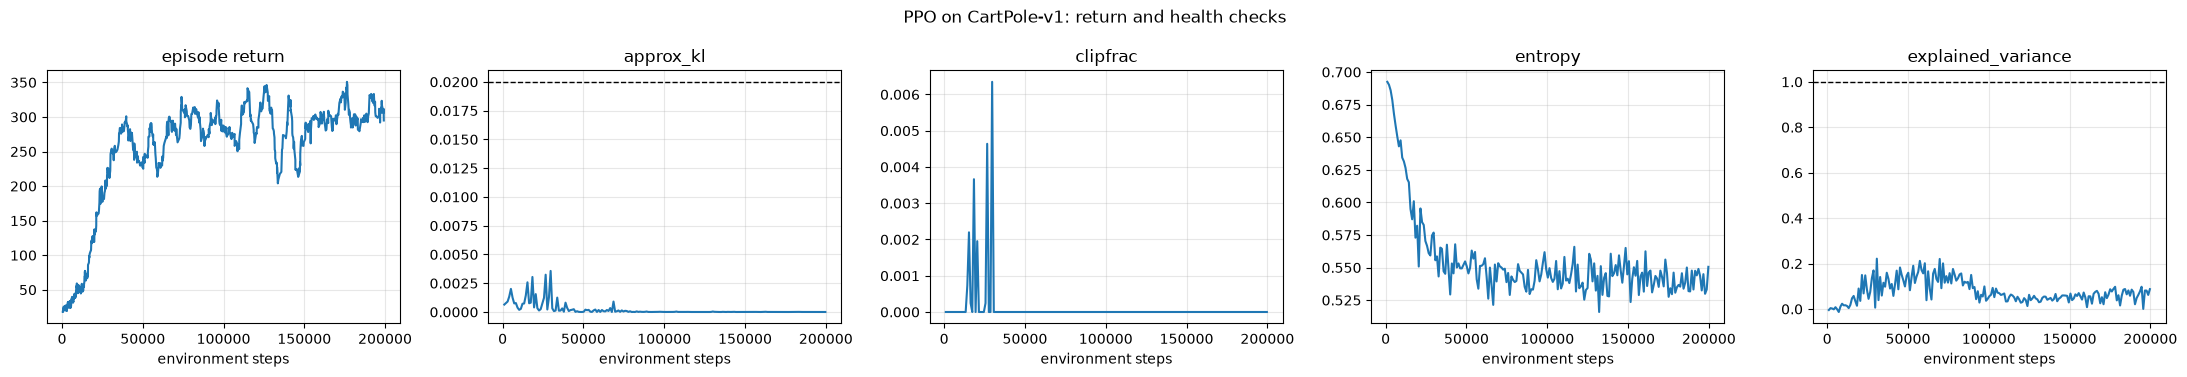

In [7]:
t0 = time.time()
ppo_cp, ppo_cp_log = train_ppo(PPOConfig(), print_every=20)
print(f"trained in {time.time() - t0:.0f}s | greedy eval: {evaluate_ppo(ppo_cp, 'CartPole-v1')}")


def plot_diagnostics(log, title):
    fig, ax = plt.subplots(1, 5, figsize=(22, 3.8))
    s = smooth(log["returns"])
    ax[0].plot(np.asarray(log["steps"])[len(log["steps"]) - len(s):], s); ax[0].set_title("episode return")
    for a, key, ref in zip(ax[1:], ["approx_kl", "clipfrac", "entropy", "explained_variance"],
                           [0.02, None, None, 1.0]):
        a.plot(log["update"], log[key]); a.set_title(key)
        if ref is not None:
            a.axhline(ref, color="k", ls="--", lw=1)
    for a in ax:
        a.set_xlabel("environment steps"); a.grid(alpha=.3)
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_diagnostics(ppo_cp_log, "PPO on CartPole-v1: return and health checks")

## A2. What do the epochs and the clipping buy us?

PPO with **1 epoch, 1 mini-batch and no clipping** is just A2C with longer rollouts. Each sample gets used once.
Comparing them at the same number of environment steps shows the value of **sample reuse**. A third run uses
**10 epochs without clipping**: lots of reuse with nothing holding the policy back. That's what clipping protects against.

PPO (4 epochs, clip 0.2)               final return  294.9 | mean approx_kl 0.0002
A2C-like (1 epoch, 1 batch, no clip)   final return   39.0 | mean approx_kl -0.0000
10 epochs, NO clip                     final return  500.0 | mean approx_kl 0.0074


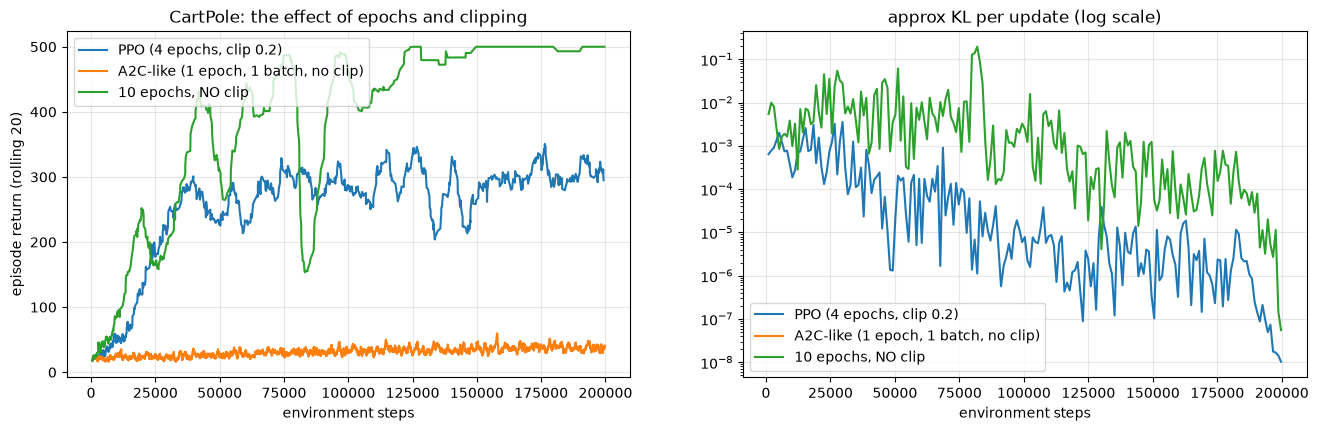

In [8]:
variants = {
    "PPO (4 epochs, clip 0.2)": PPOConfig(),
    "A2C-like (1 epoch, 1 batch, no clip)": PPOConfig(update_epochs=1, n_minibatches=1, clip_coef=1e9, clip_vloss=False),
    "10 epochs, NO clip": PPOConfig(update_epochs=10, clip_coef=1e9, clip_vloss=False),
}
variant_logs = {}
for name, cfg in variants.items():
    _, variant_logs[name] = train_ppo(cfg, verbose=False)
    print(f"{name:<38} final return {np.mean(variant_logs[name]['returns'][-20:]):6.1f} "
          f"| mean approx_kl {np.mean(variant_logs[name]['approx_kl']):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
plot_returns(variant_logs, "CartPole: the effect of epochs and clipping", ax=ax[0])
for name, log in variant_logs.items():
    ax[1].plot(log["update"], log["approx_kl"], label=name)
ax[1].set(yscale="log", xlabel="environment steps", title="approx KL per update (log scale)")
ax[1].legend(); ax[1].grid(alpha=.3); plt.show()

**What to look for:**
- **The A2C-like run learns more slowly per environment step**, because each sample is used only once.
- **Ten unclipped epochs** usually show a much larger KL per update, and a less stable learning curve.
- **Clipping keeps KL small** while still allowing several passes over the data.
- Results vary between seeds, so for a solid conclusion, rerun with a few seeds, as in notebook 5, Part D.

## A3. (Optional) LunarLander
The same code. Observation normalization helps here, because LunarLander's features have very different scales.
PPO typically reaches the "solved" score of 200 within roughly 1M steps, though it varies by seed.

In [9]:
RUN_LUNAR = False
if RUN_LUNAR:
    lunar_cfg = PPOConfig(env_id="LunarLander-v3", total_steps=1_000_000, n_envs=16, n_steps=128,
                          lr=3e-4, gamma=0.999, gae_lambda=0.98, ent_coef=0.01, norm_obs=True)
    ppo_lunar, ppo_lunar_log = train_ppo(lunar_cfg, print_every=50)
    print("greedy eval:", evaluate_ppo(ppo_lunar, "LunarLander-v3"))
    plot_diagnostics(ppo_lunar_log, "PPO on LunarLander-v3")

# Part B: Curiosity with Random Network Distillation (RND)

## The sparse-reward problem
In Pyramids from the course, the agent gets a reward only after a long, specific sequence: press a button, find the
pyramid, knock it over, reach the brick. A random policy almost never gets there, so the advantages are all ≈ 0 and
**there is nothing to learn from**. ε-greedy or entropy-based exploration is *undirected*: it doesn't push the
agent toward places it hasn't been.

## The idea: reward novelty
**RND** (Burda et al., 2018) gives the agent an **intrinsic reward** for visiting *unfamiliar* states:
1. A **target** network $f$ with fixed random weights maps each state to an embedding. It is never trained.
2. A **predictor** network $\hat f$ is trained to imitate it, using the states the agent visits.
3. The intrinsic reward is the prediction error, $r^{\text{int}}_t = \lVert \hat f(s_{t+1}) - f(s_{t+1}) \rVert^2$.

For states the agent has visited often, the predictor has learned the target, so the error and the bonus are low.
**New** states have a high error, so they pay a bonus. The agent is drawn toward the edge of what it has explored.

The curiosity is not "fooled" by randomness the way next-state prediction can be (the "noisy TV" problem), because the
target is a *deterministic* function of the state.

## Implementation details from the paper (all in `train_ppo` above)
- **Two value heads**, one for the extrinsic and one for the intrinsic return: they have different scales and dynamics.
- The **intrinsic return is non-episodic**. Curiosity continues across episode resets, so the GAE ignores `dones`.
- **Normalization:**
  - RND inputs are normalized with running statistics and clipped to [−5, 5].
  - The intrinsic reward is divided by the running standard deviation of its discounted sum.
- **Combined advantage** $A = c_{\text{ext}} A^{\text{ext}} + c_{\text{int}} A^{\text{int}}$, with $c_{\text{ext}} = 2$ and $c_{\text{int}} = 1$.
- The predictor trains on only **25% of each mini-batch**, so curiosity fades slowly rather than instantly.

In ML-Agents, all of this hides behind adding `rnd:` under `reward_signals:` in the YAML. That's the "RND" in the course's `PyramidsRND.yaml`.

## Our sparse-reward testbed: MountainCar
An under-powered car in a valley must rock back and forth to reach the flag on the right hill. The reward is −1 per step
until the flag, and episodes are cut off after 200 steps. Before the agent reaches the flag even once, every action
looks equally bad, so the extrinsic signal carries no information about *which* way to go. That's a miniature
Pyramids, and it trains in minutes on a CPU.

In [10]:
mc_base = PPOConfig(env_id="MountainCar-v0", total_steps=300_000, n_envs=16, n_steps=128,
                    lr=3e-4, gamma=0.99, gae_lambda=0.95, ent_coef=0.01, norm_obs=True, record_states=True)
mc_configs = {
    "PPO": mc_base,
    "PPO + RND": replace(mc_base, rnd=True, ext_coef=2.0, int_coef=1.0, int_gamma=0.99),
}

mc_logs, mc_agents = {}, {}
for name, cfg in mc_configs.items():
    print(f"--- {name}")
    t0 = time.time()
    mc_agents[name], mc_logs[name] = train_ppo(cfg, print_every=30)
    rets = np.array(mc_logs[name]["returns"])
    first = next((s for s, r in zip(mc_logs[name]["steps"], rets) if r > -200), None)
    print(f"{name}: reached the flag in {np.mean(rets > -200):.1%} of episodes | first success at step "
          f"{first if first else 'never'} | greedy eval {evaluate_ppo(mc_agents[name], 'MountainCar-v0')} "
          f"| {time.time() - t0:.0f}s\n")

--- PPO
step   61,440 | return  -200.0 | kl 0.0002 | clipfrac 0.00 | entropy 1.092 | 58201 SPS
step  122,880 | return  -200.0 | kl 0.0000 | clipfrac 0.00 | entropy 1.097 | 57833 SPS
step  184,320 | return  -200.0 | kl 0.0000 | clipfrac 0.00 | entropy 1.097 | 58211 SPS
step  245,760 | return  -200.0 | kl 0.0000 | clipfrac 0.00 | entropy 1.095 | 58516 SPS
step  299,008 | return  -200.0 | kl 0.0000 | clipfrac 0.00 | entropy 1.097 | 58763 SPS
PPO: reached the flag in 0.0% of episodes | first success at step never | greedy eval (-149.5, 8.357631243360764) | 5s

--- PPO + RND
step   61,440 | return  -200.0 | kl 0.0000 | clipfrac 0.00 | entropy 1.097 | int_rew 0.000 | 29763 SPS
step  122,880 | return  -198.7 | kl 0.0001 | clipfrac 0.00 | entropy 1.047 | int_rew 0.000 | 29059 SPS
step  184,320 | return  -200.0 | kl 0.0000 | clipfrac 0.00 | entropy 1.063 | int_rew 0.000 | 29048 SPS
step  245,760 | return  -200.0 | kl 0.0000 | clipfrac 0.00 | entropy 1.053 | int_rew 0.000 | 29050 SPS
step  299,0

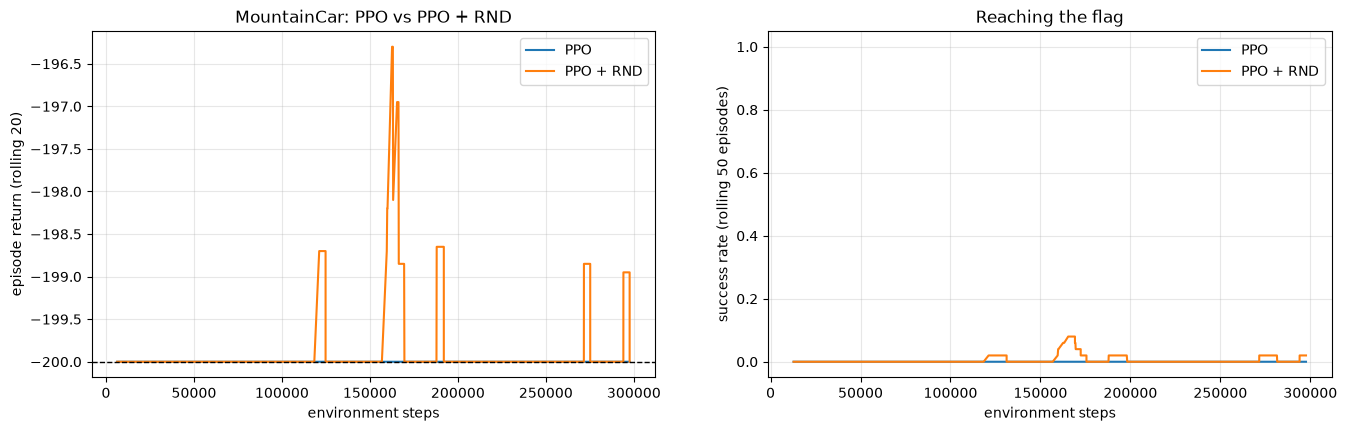

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
plot_returns(mc_logs, "MountainCar: PPO vs PPO + RND", ax=ax[0], hline=-200)

for name, log in mc_logs.items():
    success = (np.array(log["returns"]) > -200).astype(float)
    s = smooth(success, 50)
    ax[1].plot(np.asarray(log["steps"])[len(log["steps"]) - len(s):], s, label=name)
ax[1].set(xlabel="environment steps", ylabel="success rate (rolling 50 episodes)", title="Reaching the flag", ylim=(-0.05, 1.05))
ax[1].legend(); ax[1].grid(alpha=.3); plt.show()

### Where did each agent go? State-visitation heat maps

Each panel is a 2-D histogram of every state visited during training (position × velocity). The flag is at position 0.5.
Plain PPO tends to stay in a small blob around the valley floor. RND pushes the agent out into high-velocity,
far-away states, until it stumbles onto the flag. After that, the extrinsic reward takes over.

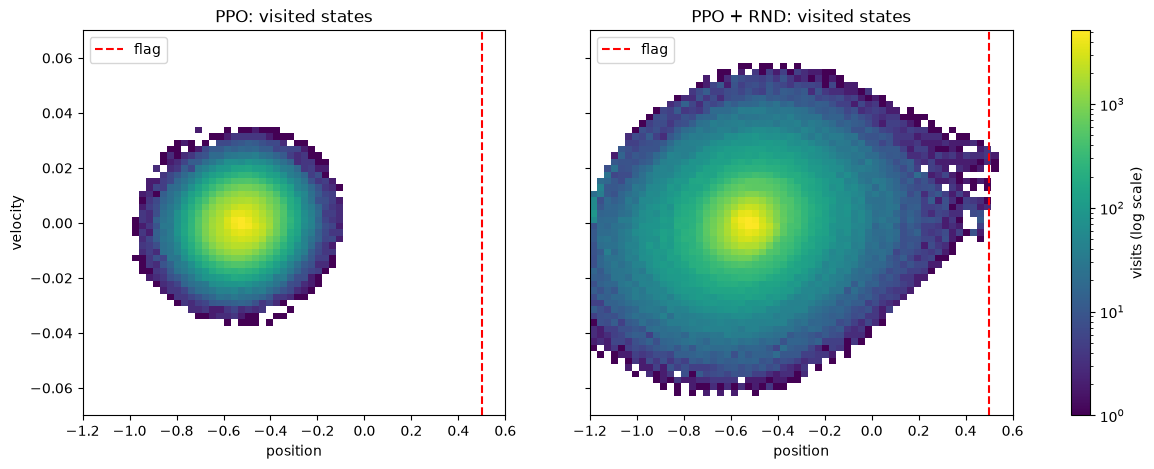

In [12]:
from matplotlib.colors import LogNorm

fig, ax = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for a, (name, log) in zip(ax, mc_logs.items()):
    states = np.concatenate(log["states"])
    h = a.hist2d(states[:, 0], states[:, 1], bins=[60, 60], range=[[-1.2, 0.6], [-0.07, 0.07]],
                 cmap="viridis", norm=LogNorm())
    a.axvline(0.5, color="red", ls="--", label="flag")
    a.set(title=f"{name}: visited states", xlabel="position")
    a.legend(loc="upper left")
ax[0].set_ylabel("velocity")
fig.colorbar(h[3], ax=ax, label="visits (log scale)"); plt.show()

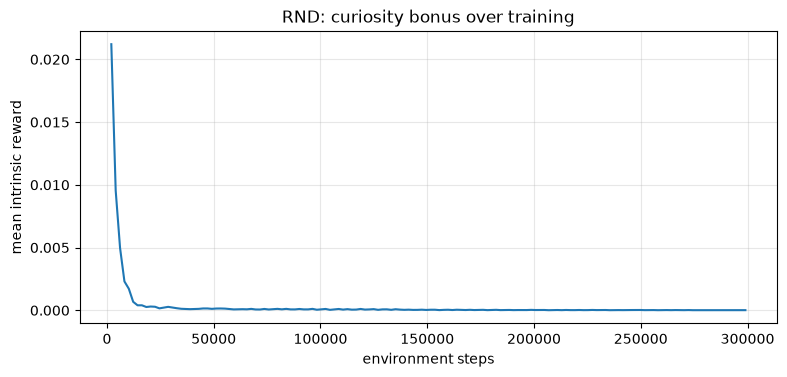

In [13]:
# How curiosity evolves: the (normalized) intrinsic reward per update
log_rnd = mc_logs["PPO + RND"]
plt.figure(figsize=(9, 3.8))
plt.plot(log_rnd["update"], log_rnd["int_reward"])
plt.xlabel("environment steps"); plt.ylabel("mean intrinsic reward")
plt.title("RND: curiosity bonus over training"); plt.grid(alpha=.3); plt.show()

**What to look for**
- **Success rate:** RND typically discovers the flag much earlier. Plain PPO may never find it within the budget, or only
  by luck on some seeds. Run 2–3 seeds before drawing conclusions; exploration results are especially seed-dependent.
- **Heat maps:** RND's visits cover a much wider range of positions and velocities.
- **Intrinsic reward:** it changes as the predictor catches up on familiar states. The normalization keeps its *scale* roughly
  constant, but the bonus keeps moving toward whatever is still new.

Try `int_coef=0.0` with `rnd=True`, which gives the same networks with no curiosity, and `int_coef` values of 0.5 or 2.0.

# Part C: MiniGrid DoorKey, our "Pyramids"

[MiniGrid](https://minigrid.farama.org/) (Farama Foundation) is the standard benchmark for exploration methods like RND.
In **DoorKey** the agent must:
1. find the **key**,
2. pick it up and walk to the locked **door**,
3. open the door, and
4. reach the green **goal** square.

That's the same kind of long, specific chain of actions as Pyramids: press the button, knock over the pyramid, reach the brick.
- **Reward:** only on reaching the goal, $1 - 0.9 \cdot \frac{\text{steps}}{\text{max steps}}$, and 0 otherwise.
  A random agent almost never sees a reward.
- **Observation:** an egocentric **7×7 view**. Each cell is (object, color, state), so walls block the agent's view.
  We **one-hot encode** it into a flat vector, so the MLP-based PPO from Part A works unchanged.
- **Actions:** 7: turn left, turn right, forward, pick up, drop, toggle (open a door), done.
- **Layout:** the walls, door, key and goal are randomized every episode, so the agent can't memorize a single path.

In [14]:
import minigrid                                      # registers the MiniGrid-* environments with gymnasium
from minigrid.core.constants import COLOR_TO_IDX, OBJECT_TO_IDX, STATE_TO_IDX

print("minigrid", getattr(minigrid, "__version__", "?"))


class OneHotPartialObs(gym.ObservationWrapper):
    '''MiniGrid dict observation -> flat float vector: one-hot (object, color, state) per cell + one-hot direction.'''
    def __init__(self, env):
        super().__init__(env)
        self.h, self.w, _ = env.observation_space["image"].shape
        self.eye_obj = np.eye(len(OBJECT_TO_IDX), dtype=np.float32)
        self.eye_col = np.eye(len(COLOR_TO_IDX), dtype=np.float32)
        self.eye_state = np.eye(len(STATE_TO_IDX), dtype=np.float32)
        self.eye_dir = np.eye(4, dtype=np.float32)
        dim = self.h * self.w * (len(OBJECT_TO_IDX) + len(COLOR_TO_IDX) + len(STATE_TO_IDX)) + 4
        self.observation_space = gym.spaces.Box(0.0, 1.0, shape=(dim,), dtype=np.float32)

    def observation(self, obs):
        img = obs["image"]
        cells = np.concatenate([self.eye_obj[img[..., 0]], self.eye_col[img[..., 1]], self.eye_state[img[..., 2]]], axis=-1)
        return np.concatenate([cells.reshape(-1), self.eye_dir[obs["direction"]]])


def make_minigrid(env_id, render_mode=None):
    return OneHotPartialObs(gym.make(env_id, render_mode=render_mode))


SMALL_ID = "MiniGrid-DoorKey-5x5-v0"      # easy: PPO alone usually solves it
BIG_ID = "MiniGrid-DoorKey-8x8-v0"        # sparse enough that exploration matters

probe = make_minigrid(BIG_ID)
o, _ = probe.reset(seed=0)
print("observation vector:", o.shape, "| actions:", probe.action_space.n,
      "| max steps per episode:", probe.unwrapped.max_steps)
print("mission:", probe.unwrapped.mission)
probe.close()

minigrid 3.1.0
observation vector: (984,) | actions: 7 | max steps per episode: 640
mission: use the key to open the door and then get to the goal


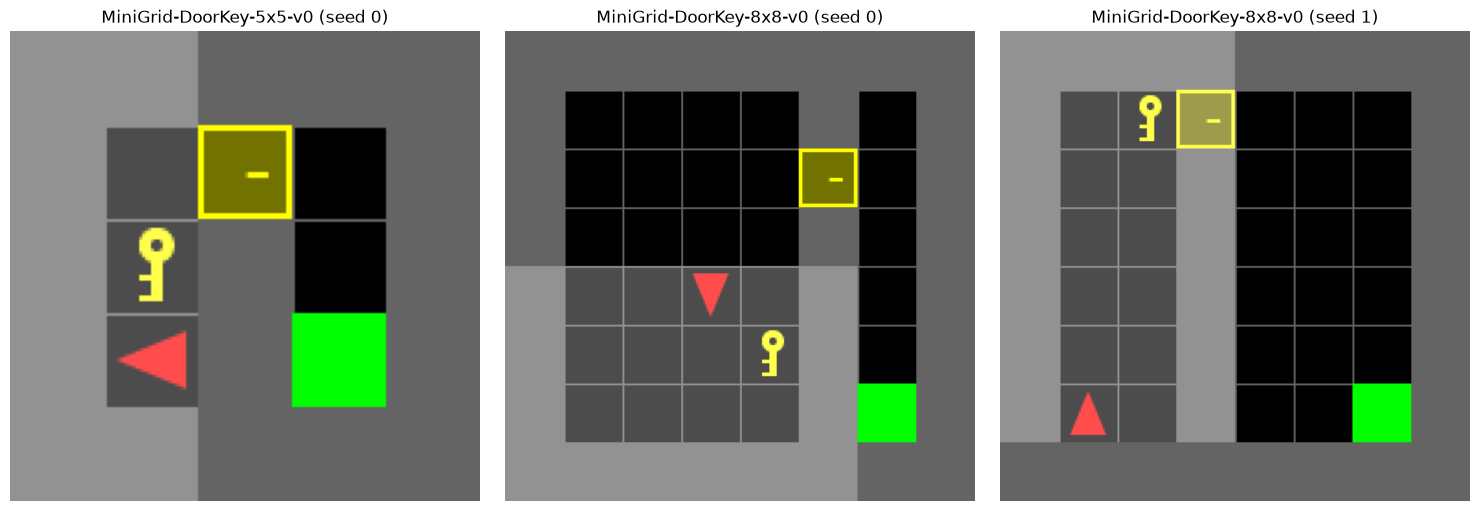

random policy success rate on MiniGrid-DoorKey-5x5-v0: 8.0%
random policy success rate on MiniGrid-DoorKey-8x8-v0: 3.0%


In [15]:
# What it looks like (full top-down render; the agent itself only sees the lighter 7x7 area in front of it)
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, (env_id, seed) in zip(ax, [(SMALL_ID, 0), (BIG_ID, 0), (BIG_ID, 1)]):
    e = gym.make(env_id, render_mode="rgb_array")
    e.reset(seed=seed)
    a.imshow(e.render()); a.set_title(f"{env_id} (seed {seed})"); a.axis("off")
    e.close()
plt.tight_layout(); plt.show()


def random_success_rate(env_id, episodes=200, seed=0):
    e = make_minigrid(env_id)
    e.action_space.seed(seed)
    wins = 0
    for ep in range(episodes):
        e.reset(seed=seed + ep)
        done = False
        while not done:
            _, r, term, trunc, _ = e.step(e.action_space.sample())
            done = term or trunc
        wins += r > 0
    e.close()
    return wins / episodes

for env_id in (SMALL_ID, BIG_ID):
    print(f"random policy success rate on {env_id}: {random_success_rate(env_id):.1%}")

## C1. Sanity check: DoorKey-5x5 with plain PPO

On the small map, random exploration finds the goal often enough for plain PPO to learn. These settings are similar to
the widely used `rl-starter-files` for MiniGrid: 16 environments, 128-step rollouts, 4 epochs.
Expect about 5–10 minutes on a CPU.

step   40,960 | return     1.0 | kl 0.0237 | clipfrac 0.13 | entropy 0.310 | 9070 SPS
step   81,920 | return     1.0 | kl 0.0005 | clipfrac 0.02 | entropy 0.029 | 8842 SPS
step  122,880 | return     1.0 | kl 0.0194 | clipfrac 0.01 | entropy 0.019 | 8689 SPS
step  163,840 | return     1.0 | kl 0.0076 | clipfrac 0.00 | entropy 0.022 | 8560 SPS
step  204,800 | return     1.0 | kl 0.0021 | clipfrac 0.00 | entropy 0.004 | 8486 SPS
step  245,760 | return     1.0 | kl 0.0118 | clipfrac 0.01 | entropy 0.003 | 8434 SPS
step  286,720 | return     1.0 | kl 0.0000 | clipfrac 0.00 | entropy 0.002 | 8434 SPS
step  299,008 | return     1.0 | kl 0.0000 | clipfrac 0.00 | entropy 0.003 | 8435 SPS
trained in 0.6 min | greedy eval: (0.9632800000000001, 0.007687496341462525)


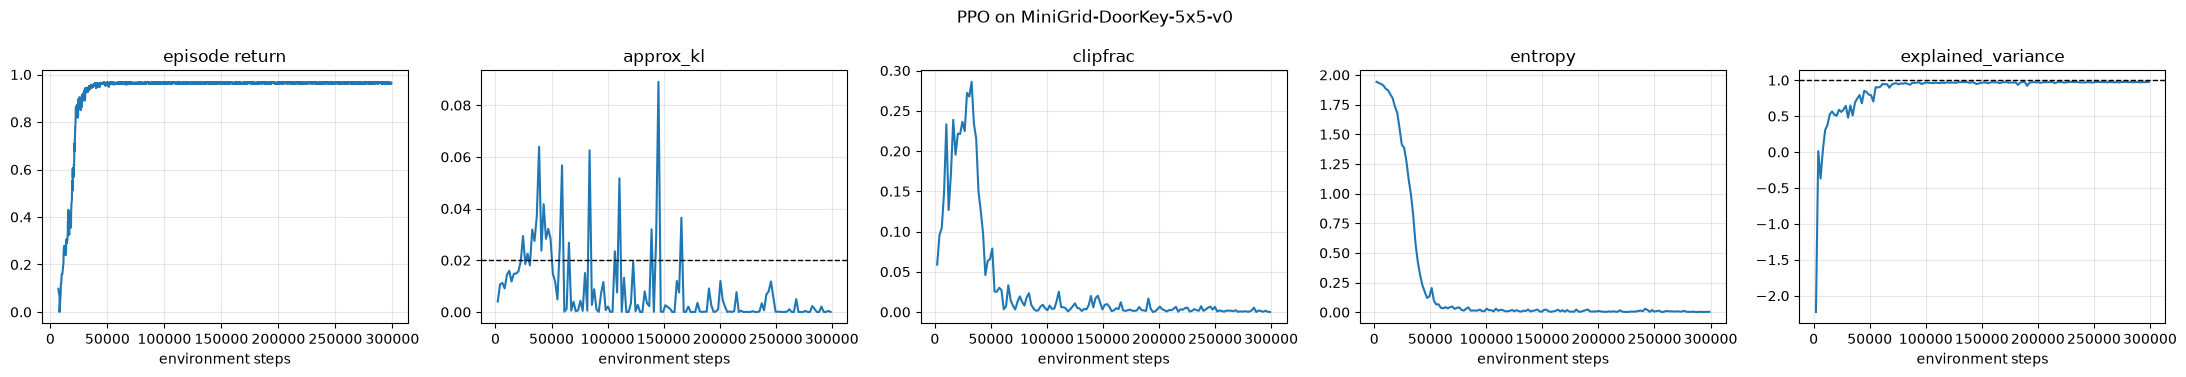

In [16]:
mg_base = PPOConfig(
    env_id=SMALL_ID, make_env=lambda: make_minigrid(SMALL_ID),
    total_steps=300_000, n_envs=16, n_steps=128, update_epochs=4, n_minibatches=8,
    lr=5e-4, gamma=0.99, gae_lambda=0.95, ent_coef=0.01, hidden=256,
)

t0 = time.time()
mg_small_agent, mg_small_log = train_ppo(mg_base, print_every=20)
print(f"trained in {(time.time() - t0) / 60:.1f} min | greedy eval:",
      evaluate_ppo(mg_small_agent, SMALL_ID, make_env=lambda: make_minigrid(SMALL_ID)))
plot_diagnostics(mg_small_log, f"PPO on {SMALL_ID}")

## C2. DoorKey-8x8: PPO vs PPO + RND

On the bigger map, rewards become rare. The episode limit is 640 steps, and a random agent almost never finishes.
We train both agents with the same budget and record the agent's **grid position** after every step, to see *where* each one explores.

Expect roughly 15–40 minutes per run on a CPU for 1M steps. Lower `BIG_STEPS` for a quicker look.
Exploration results vary a lot between seeds, so if you have time, repeat with `seed=2` and `seed=3`.

In [17]:
BIG_STEPS = 1_000_000
agent_pos = lambda e: np.asarray(e.unwrapped.agent_pos)

big_ppo = replace(mg_base, env_id=BIG_ID, make_env=lambda: make_minigrid(BIG_ID),
                  total_steps=BIG_STEPS, record_info_fn=agent_pos)
big_configs = {
    "PPO": big_ppo,
    "PPO + RND": replace(big_ppo, rnd=True, ext_coef=2.0, int_coef=1.0, int_gamma=0.99, rnd_lr=1e-4),
}

big_logs, big_agents = {}, {}
for name, cfg in big_configs.items():
    print(f"--- {name}")
    t0 = time.time()
    big_agents[name], big_logs[name] = train_ppo(cfg, print_every=50)
    rets = np.array(big_logs[name]["returns"])
    first = next((s for s, r in zip(big_logs[name]["steps"], rets) if r > 0), None)
    print(f"{name}: success in {np.mean(rets > 0):.1%} of training episodes | first success at step "
          f"{first if first else 'never'} | greedy eval "
          f"{evaluate_ppo(big_agents[name], BIG_ID, make_env=lambda: make_minigrid(BIG_ID))} "
          f"| {(time.time() - t0) / 60:.1f} min\n")

--- PPO
step  102,400 | return     0.0 | kl 0.0083 | clipfrac 0.13 | entropy 1.758 | 8551 SPS
step  204,800 | return     0.0 | kl 0.0081 | clipfrac 0.13 | entropy 1.555 | 8388 SPS
step  307,200 | return     0.0 | kl 0.0087 | clipfrac 0.09 | entropy 1.666 | 8454 SPS
step  409,600 | return     0.0 | kl 0.0103 | clipfrac 0.10 | entropy 1.621 | 8355 SPS
step  512,000 | return     0.0 | kl 0.0095 | clipfrac 0.11 | entropy 1.566 | 8346 SPS
step  614,400 | return     0.3 | kl 0.0043 | clipfrac 0.06 | entropy 1.346 | 8368 SPS
step  716,800 | return     0.8 | kl 0.0065 | clipfrac 0.07 | entropy 0.926 | 8397 SPS
step  819,200 | return     1.0 | kl 0.0029 | clipfrac 0.02 | entropy 0.193 | 8352 SPS
step  921,600 | return     1.0 | kl 0.0022 | clipfrac 0.01 | entropy 0.152 | 8349 SPS
step  999,424 | return     1.0 | kl 0.0000 | clipfrac 0.00 | entropy 0.101 | 8343 SPS
PPO: success in 92.1% of training episodes | first success at step 105376 | greedy eval (0.971453125, 0.006000915457505219) | 2.0 mi

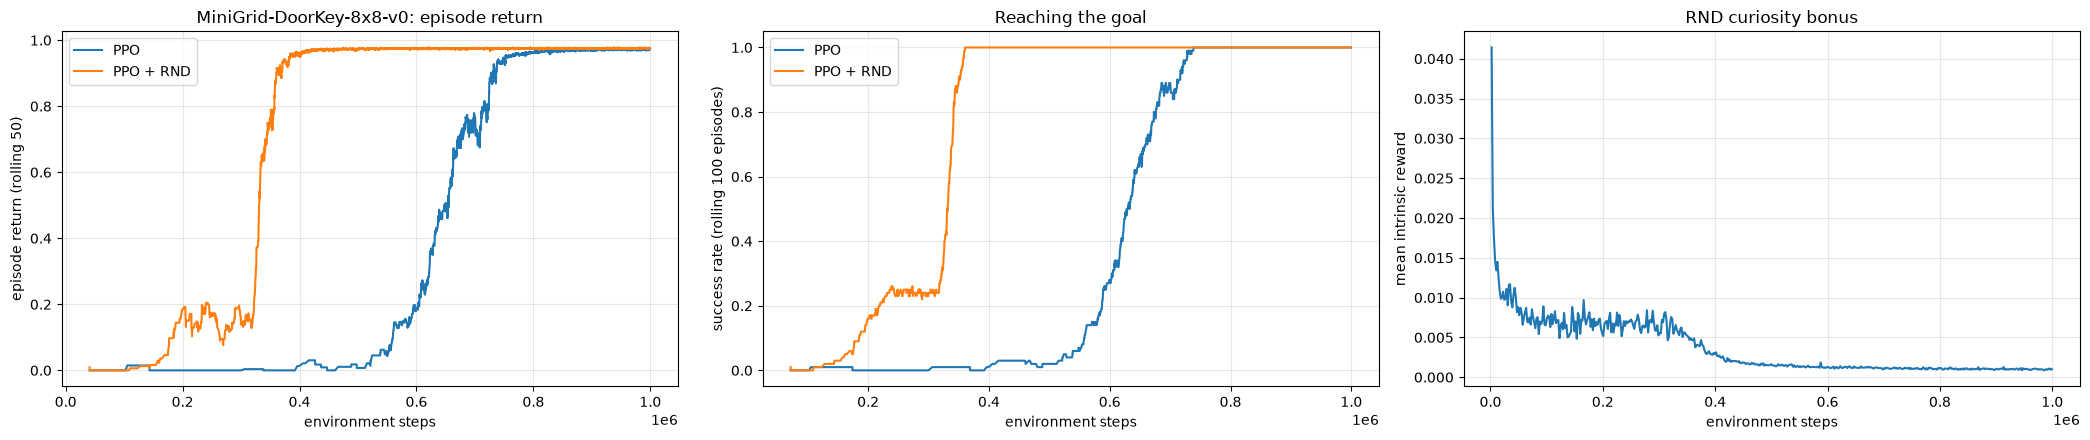

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(21, 4.5))
plot_returns(big_logs, f"{BIG_ID}: episode return", k=50, ax=ax[0])

for name, log in big_logs.items():
    success = (np.array(log["returns"]) > 0).astype(float)
    s = smooth(success, 100)
    ax[1].plot(np.asarray(log["steps"])[len(log["steps"]) - len(s):], s, label=name)
ax[1].set(xlabel="environment steps", ylabel="success rate (rolling 100 episodes)", title="Reaching the goal",
          ylim=(-0.05, 1.05))
ax[1].legend(); ax[1].grid(alpha=.3)

ax[2].plot(big_logs["PPO + RND"]["update"], big_logs["PPO + RND"]["int_reward"])
ax[2].set(xlabel="environment steps", ylabel="mean intrinsic reward", title="RND curiosity bonus")
ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

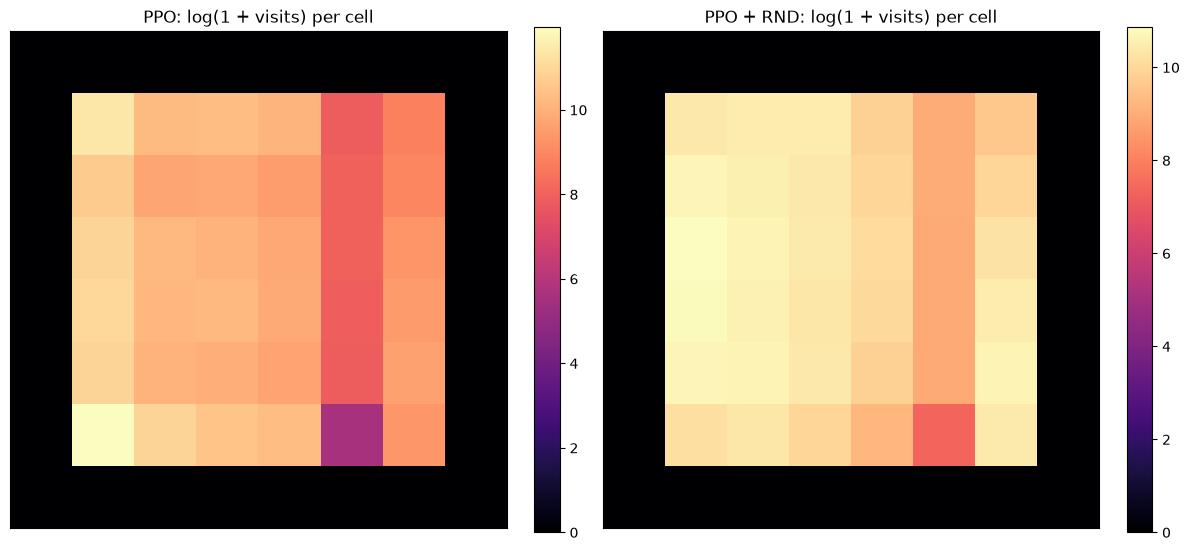

In [18]:
# Where did each agent spend its time? Heat map of grid positions over ALL of training.
grid_w, grid_h = 8, 8
fig, ax = plt.subplots(1, 2, figsize=(12, 5.5))
for a, (name, log) in zip(ax, big_logs.items()):
    pos = np.stack(log["info"])
    counts, _, _ = np.histogram2d(pos[:, 1], pos[:, 0], bins=[grid_h, grid_w], range=[[0, grid_h], [0, grid_w]])
    im = a.imshow(np.log1p(counts), cmap="magma")
    a.set_title(f"{name}: log(1 + visits) per cell"); a.set_xticks([]); a.set_yticks([])
    fig.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()

**What to look for**
- **Success rate:** RND typically finds the goal earlier and more reliably within the same budget. Plain PPO often stays
  at 0% for a long time on 8×8, and may or may not take off within 1M steps.
- **Heat maps:** the layout changes every episode, so this is a rough picture, but RND's visits are usually spread over
  more of the grid, including the room behind the door.
- **Curiosity bonus:** high early on, while everything is new, then moving to whatever is still unfamiliar.

**Harder variants to try:** `MiniGrid-DoorKey-16x16-v0`, `MiniGrid-KeyCorridorS3R3-v0` and `MiniGrid-MultiRoom-N4-S5-v0`.
Plain PPO almost never solves these without an exploration bonus.

### Watch the trained agent

In [21]:
import imageio


def record_minigrid_gif(agent, env_id, path, seed=0, max_steps=200, fps=6):
    env = make_minigrid(env_id, render_mode="rgb_array")
    o, _ = env.reset(seed=seed)
    frames = [env.render()]
    for _ in range(max_steps):
        with torch.no_grad():
            a = int(agent.dist(torch.as_tensor(o).unsqueeze(0)).probs.argmax())
        o, r, term, trunc, _ = env.step(a)
        frames.append(env.render())
        if term or trunc:
            break
    env.close()
    imageio.mimsave(path, frames, duration=int(1000 / fps), loop=0)    # GIF frame duration in ms (imageio >= 2.28)
    print(f"{path}: {len(frames)} frames, reward {r:.2f}")


for name, agent in big_agents.items():
    record_minigrid_gif(agent, BIG_ID, f"doorkey8x8_{name.replace(' ', '').replace('+', '_')}.gif")

doorkey8x8_PPO.gif: 18 frames, reward 0.98
doorkey8x8_PPO_RND.gif: 18 frames, reward 0.98


# Part D: The same task with Ray RLlib

In Parts A to C we wrote every line of PPO. In practice you'd usually use a library, and
[RLlib](https://docs.ray.io/en/latest/rllib/index.html) is the most widely used one that **scales**:
- **`EnvRunner` actors** collect experience in parallel processes, across all your cores or a whole cluster.
- **`Learner`s** do the gradient updates, on one or several GPUs.
- One `AlgorithmConfig` describes everything, and it plugs straight into **Ray Tune** (notebook 4).

It plays the role `mlagents-learn` plays in the course, but for any Gymnasium environment.

This uses RLlib's **new API stack**, the default since Ray 2.40: `build_algo()`, `num_epochs`, `minibatch_size`,
`DefaultModelConfig`. Older tutorials use names like `num_sgd_iter` and `sgd_minibatch_size`; those are the old stack.

| Our `PPOConfig` | RLlib `PPOConfig` |
|---|---|
| `n_envs` (one process) | `env_runners(num_env_runners=…, num_envs_per_env_runner=…)` (many processes) |
| `n_envs × n_steps` | `train_batch_size_per_learner` |
| `minibatch_size`, `update_epochs` | `minibatch_size`, `num_epochs` |
| `clip_coef`, `ent_coef`, `vf_coef` | `clip_param`, `entropy_coeff`, `vf_loss_coeff` |
| `gae_lambda`, `gamma`, `lr`, `max_grad_norm` | `lambda_`, `gamma`, `lr`, `grad_clip` |
| `hidden` | `DefaultModelConfig(fcnet_hiddens=[…])` |
| (no KL penalty) | `use_kl_loss=False`. RLlib *also* adds an adaptive KL penalty by default |
| RND | not built in; this is where writing it yourself pays off |

In [30]:
import ray
from ray.rllib.algorithms.ppo import PPOConfig as RLlibPPOConfig
from ray.rllib.core.rl_module.default_model_config import DefaultModelConfig
from ray.rllib.utils.metrics import ENV_RUNNER_RESULTS, EPISODE_RETURN_MEAN, NUM_ENV_STEPS_SAMPLED_LIFETIME

ray.init(ignore_reinit_error=True, include_dashboard=False)
print("ray", ray.__version__, "| CPUs:", ray.cluster_resources().get("CPU"))


class MiniGridOneHotEnv(gym.Wrapper):
    '''MiniGrid + one-hot observations, as a class RLlib can construct in every worker process.
    No register_env needed, so it keeps working after ray.shutdown(), kernel restarts or inside Tune trials.'''
    def __init__(self, config=None):
        import minigrid  # noqa: F401  (registers the MiniGrid envs inside the worker process)
        config = config or {}
        super().__init__(OneHotPartialObs(gym.make(config.get("env_id", SMALL_ID))))


register_env("minigrid-onehot", minigrid_env_creator)

2026-10-15 19:04:07,011	INFO worker.py:2033 -- Started a local Ray instance.


ray 2.59.0 | CPUs: 15.0


In [31]:
N_RUNNERS = max(1, min(4, int(ray.cluster_resources().get("CPU", 2)) - 1))   # leave one core for the learner

def rllib_ppo_config(env_id, num_env_runners=N_RUNNERS):
    return (
        RLlibPPOConfig()
        .environment(MiniGridOneHotEnv, env_config={"env_id": env_id}) 
        .env_runners(num_env_runners=num_env_runners, num_envs_per_env_runner=4)
        .training(
            lr=5e-4, gamma=0.99, lambda_=0.95,
            train_batch_size_per_learner=2048,      # = our n_envs * n_steps
            minibatch_size=256, num_epochs=4,
            clip_param=0.2, entropy_coeff=0.01, vf_loss_coeff=0.5,
            use_kl_loss=False, grad_clip=0.5,
        )
        .rl_module(model_config=DefaultModelConfig(fcnet_hiddens=[256, 256], fcnet_activation="tanh",
                                                   vf_share_layers=False))
    )


def get_metric(result, key, default=np.nan):
    '''RLlib metric keys move around between versions: look at the top level and under env_runners.'''
    if key in result:
        return result[key]
    return result.get(ENV_RUNNER_RESULTS, {}).get(key, default)


def train_rllib(config, total_steps, verbose=True):
    algo = config.build_algo()
    log = {"steps": [], "returns": []}
    t0 = time.time()
    while True:
        result = algo.train()
        steps = int(get_metric(result, NUM_ENV_STEPS_SAMPLED_LIFETIME, 0))
        ret = get_metric(result, EPISODE_RETURN_MEAN)
        log["steps"].append(steps); log["returns"].append(ret)
        if verbose and result["training_iteration"] % 10 == 0:
            print(f"iter {result['training_iteration']:>4} | steps {steps:>8,} | return mean {ret:.3f} "
                  f"| {steps / (time.time() - t0):.0f} SPS")
        if steps >= total_steps:
            break
    return algo, log

(SingleAgentEnvRunner pid=59124) objc[59124]: Class SDL_RumbleMotor is implemented in both /Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x13fdb8d40) and /Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x149fa49c8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
(SingleAgentEnvRunner pid=59124) objc[59124]: Class SDL_RumbleContext is implemented in both /Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x13fdb8d90) and /Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x149fa4a18). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
(SingleAgentEnvRunner pid=59124) objc[59124]: Class SDLApplication is implemented in both /Users/harvinder

iter   10 | steps   20,503 | return mean 0.114 | 8184 SPS
iter   20 | steps   41,037 | return mean 0.943 | 7788 SPS
iter   30 | steps   61,569 | return mean 0.962 | 7786 SPS
iter   40 | steps   82,097 | return mean 0.957 | 7813 SPS
iter   50 | steps  102,638 | return mean 0.958 | 7805 SPS
iter   60 | steps  123,157 | return mean 0.963 | 7781 SPS
iter   70 | steps  143,689 | return mean 0.964 | 7794 SPS
iter   80 | steps  164,229 | return mean 0.955 | 7763 SPS
iter   90 | steps  184,770 | return mean 0.964 | 7742 SPS
iter  100 | steps  205,301 | return mean 0.963 | 7650 SPS
iter  110 | steps  225,832 | return mean 0.965 | 7587 SPS
iter  120 | steps  246,370 | return mean 0.964 | 7579 SPS
iter  130 | steps  266,903 | return mean 0.965 | 7528 SPS
iter  140 | steps  287,433 | return mean 0.965 | 7495 SPS
RLlib trained in 0.7 min with 4 env runners


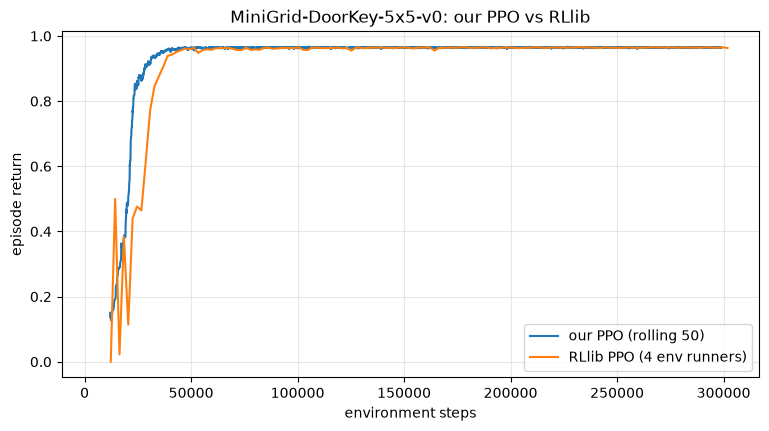

In [32]:
RLLIB_STEPS = 300_000
t0 = time.time()
rllib_algo, rllib_log = train_rllib(rllib_ppo_config(SMALL_ID), RLLIB_STEPS)
print(f"RLlib trained in {(time.time() - t0) / 60:.1f} min with {N_RUNNERS} env runners")

# Compare with our PPO from C1 (same task, similar hyperparameters).
# RLlib already reports a running mean, so we only smooth our own per-episode returns.
plt.figure(figsize=(9, 4.5))
s = smooth(mg_small_log["returns"], 50)
plt.plot(np.asarray(mg_small_log["steps"])[len(mg_small_log["steps"]) - len(s):], s, label="our PPO (rolling 50)")
plt.plot(rllib_log["steps"], rllib_log["returns"], label=f"RLlib PPO ({N_RUNNERS} env runners)")
plt.xlabel("environment steps"); plt.ylabel("episode return")
plt.title(f"{SMALL_ID}: our PPO vs RLlib"); plt.legend(); plt.grid(alpha=.3); plt.show()

Expect similar curves *per environment step*: it's the same algorithm. RLlib's advantage is **wall-clock time**,
which grows as you add env runners (and GPUs, and machines). Our single-process loop can't do that. Try
`N_RUNNERS = 1` versus the maximum, and compare the steps-per-second figures.

### Use the trained RLlib policy
The new API stack represents the policy as an `RLModule`. For inference, call `forward_inference` and turn the
action-distribution inputs (the logits) into an action.

In [33]:
def evaluate_rllib(algo, env_id, episodes=10, seed=20_000):
    module = algo.get_module()
    env = make_minigrid(env_id)
    rets = []
    for ep in range(episodes):
        o, _ = env.reset(seed=seed + ep)
        done, G = False, 0.0
        while not done:
            with torch.no_grad():
                out = module.forward_inference({"obs": torch.as_tensor(o).unsqueeze(0)})
            a = int(out["action_dist_inputs"].argmax(dim=-1)[0])            # greedy action from the logits
            o, r, term, trunc, _ = env.step(a)
            G += r
            done = term or trunc
        rets.append(G)
    env.close()
    return float(np.mean(rets)), float(np.std(rets))

print("RLlib greedy eval:", evaluate_rllib(rllib_algo, SMALL_ID))

# Save / restore (new API stack)
ckpt_dir = Path("rllib_checkpoints/doorkey5x5").absolute()
rllib_algo.save_to_path(str(ckpt_dir))
print("saved to", ckpt_dir)
# from ray.rllib.algorithms.algorithm import Algorithm
# restored = Algorithm.from_checkpoint(str(ckpt_dir))

RLlib greedy eval: (0.9643600000000001, 0.005447788542151749)
saved to /Users/harvindersingh/rl/rl-from-scratch/rllib_checkpoints/doorkey5x5


### Scale it, and tune it with Ray Tune

Because an RLlib config is a Ray Tune `param_space`, the tuning from notebook 4 is a few lines. For example, a small grid
over learning rate and entropy on DoorKey-8x8, with all trials running in parallel:

In [40]:
RUN_RLLIB_TUNE = True
if RUN_RLLIB_TUNE:
    from ray import tune
    METRIC = f"{ENV_RUNNER_RESULTS}/{EPISODE_RETURN_MEAN}"

    tune_config = (rllib_ppo_config(BIG_ID, num_env_runners=1)
                   .training(lr=tune.grid_search([2.5e-4, 5e-4, 1e-3]),
                             entropy_coeff=tune.grid_search([0.005, 0.01, 0.02])))
    tuner = tune.Tuner(
        "PPO",
        param_space=tune_config,
        run_config=tune.RunConfig(name="rllib_doorkey8x8", storage_path=str(Path("ray_results").absolute()),
                                  stop={NUM_ENV_STEPS_SAMPLED_LIFETIME: 1_000_000}),
        # no metric/mode here: early iterations on DoorKey-8x8 have no finished episodes yet,
        # and Tune would reject results without the metric. We pick the best trial afterwards.
        tune_config=tune.TuneConfig(max_concurrent_trials=4),     # each trial needs ~2 CPUs
    )
    tune_results = tuner.fit()

    if tune_results.num_errors:
        print(f"{tune_results.num_errors} trial(s) failed, first error:\n", tune_results.errors[0])
    best = tune_results.get_best_result(metric=METRIC, mode="max", scope="last")   # skips NaN values
    print("best config:", {k: best.config[k] for k in ("lr", "entropy_coeff")},
          "| final return:", best.metrics[ENV_RUNNER_RESULTS][EPISODE_RETURN_MEAN])

(PPO pid=65224) 2026-10-15 19:15:28,050	WARNING algorithm_config.py:5160 -- You are running PPO on the new API stack! This is the new default behavior for this algorithm. If you don't want to use the new API stack, set `config.api_stack(enable_rl_module_and_learner=False,enable_env_runner_and_connector_v2=False)`. For a detailed migration guide, see here: https://docs.ray.io/en/master/rllib/new-api-stack-migration-guide.html
(PPO pid=65224) [2026-10-15 19:15:28,103 E 65224 28433132] core_worker.cc:2297: Actor with class name: 'SingleAgentEnvRunner' and ID: '4d012a76ab49e69b81dfebff01000000' has constructor arguments in the object store and max_restarts > 0. If the arguments in the object store go out of scope or are lost, the actor restart will fail. See https://github.com/ray-project/ray/issues/53727 for more details.
(SingleAgentEnvRunner pid=65260) objc[65260]: Class SDL_RumbleMotor is implemented in both /Users/harvindersingh/miniforge3/envs/rl/lib/python3.11/site-packages/cv2/.dyl

best config: {'lr': 0.0005, 'entropy_coeff': 0.01} | final return: 0.97564375


In [41]:
rllib_algo.stop()
ray.shutdown()

# Part E (appendix): Unity ML-Agents, if you still want it

ML-Agents is still the way to train agents *inside Unity games*. Unity keeps updating the C# package. But the Python
trainer (version **1.1.0**) is effectively frozen:
- It requires Python **3.10.1–3.10.12**, nothing newer. pip shows only old 0.x versions on any other Python.
- It pins old NumPy and protobuf versions, so it needs its own environment:

```bash
conda create -n mlagents python=3.10.12 -y && conda activate mlagents
python --version                      # must print 3.10.12 (or another 3.10.x <= .12)
python -m pip install mlagents==1.1.0
```

- The course's SnowballTarget and Pyramids builds are **Linux executables**. On macOS or Windows, use Colab or a Linux
  machine, or open ML-Agents' example project in the Unity Editor and build or train it there.

The concepts map one-to-one onto this notebook, which makes the course's YAML files easy to read:

| ML-Agents YAML | Our `PPOConfig` | RLlib |
|---|---|---|
| `max_steps` | `total_steps` | stop criterion |
| `buffer_size` | `n_envs × n_steps` | `train_batch_size_per_learner` |
| `batch_size` | `minibatch_size` | `minibatch_size` |
| `num_epoch` | `update_epochs` | `num_epochs` |
| `learning_rate`, `learning_rate_schedule: linear` | `lr`, `anneal_lr` | `lr` (a schedule is also possible) |
| `epsilon` | `clip_coef` | `clip_param` |
| `beta` | `ent_coef` | `entropy_coeff` |
| `lambd` | `gae_lambda` | `lambda_` |
| `time_horizon` | ≈ `n_steps` | `rollout_fragment_length` |
| `network_settings.normalize` | `norm_obs` | an observation-normalization connector |
| `hidden_units`, `num_layers` | `hidden` | `fcnet_hiddens` |
| `reward_signals.extrinsic.gamma / strength` | `gamma` / `ext_coef` | `gamma` |
| `reward_signals.rnd.gamma / strength / learning_rate` | `int_gamma` / `int_coef` / `rnd_lr` | (custom) |
| many agents per scene, `--num-envs` | `n_envs` | `num_env_runners`, `num_envs_per_env_runner` |

**Modern alternatives for "real" 3D and game environments**
- [Gymnasium MuJoCo](https://gymnasium.farama.org/environments/mujoco/) (Ant, Humanoid): `pip install "gymnasium[mujoco]"`, and it runs on Apple Silicon.
- [Godot RL Agents](https://github.com/edbeeching/godot_rl_agents): an open-source game engine with RL, used in the HF course's bonus unit.
- [MuJoCo Playground / MJX](https://github.com/google-deepmind/mujoco_playground) and Brax: GPU-accelerated physics in JAX.

# Summary and next steps

| Concept | Where we built it |
|---|---|
| Clipped surrogate, epochs, mini-batches | `train_ppo` (Part A) |
| PPO health checks | `plot_diagnostics` |
| RND curiosity: target and predictor, two value heads, non-episodic intrinsic return | `RND`, `train_ppo` (Part B) |
| A sparse-reward benchmark | MiniGrid DoorKey (Part C) |
| Scalable, library-grade PPO | RLlib (Part D) |

**Key takeaways**
- PPO = A2C + **safe sample reuse**: clipping lets every rollout be used for several epochs.
- With sparse rewards, **directed exploration** like RND can decide whether an agent learns at all.
- Write algorithms yourself to understand them. Use RLlib or similar to **scale** them.

**Next steps**
- **Continuous control:** the Gaussian policy from notebook 5 plus PPO on Gymnasium MuJoCo (`HalfCheetah-v5`, `Ant-v5`), or SAC.
- **Multi-agent and self-play** (course Unit 7): RLlib's `MultiAgentEnv`, or PettingZoo environments.
- **A CNN encoder** for MiniGrid's 7×7×3 view instead of one-hot + MLP, which matters on bigger maps.

## References
- Hugging Face Deep RL Course, [Unit 5](https://huggingface.co/learn/deep-rl-course/unit5/introduction) and [Unit 8 (PPO)](https://huggingface.co/learn/deep-rl-course/unit8/introduction)
- Schulman et al., 2017, *Proximal Policy Optimization Algorithms*
- Huang et al., 2022, *The 37 Implementation Details of Proximal Policy Optimization*
- Burda et al., 2018, *Exploration by Random Network Distillation*
- Chevalier-Boisvert et al., 2023, *Minigrid & Miniworld: Modular & Customizable RL Environments*
- Liang et al., 2018, *RLlib: Abstractions for Distributed Reinforcement Learning*, and the [RLlib docs](https://docs.ray.io/en/latest/rllib/index.html)
- [CleanRL](https://github.com/vwxyzjn/cleanrl): `ppo.py` and `ppo_rnd_envpool.py`